# 13 — Proof-of-Concept Story and Visual Summary

## Workflow overview

This notebook summarizes the full proof-of-concept pipeline developed in the repository.

The workflow connects:

**urban form → thermal simulation → thermalized walking network → accessibility analysis → observed mobility comparison**

The figure below provides a compact overview of the analytical stages and their outputs.

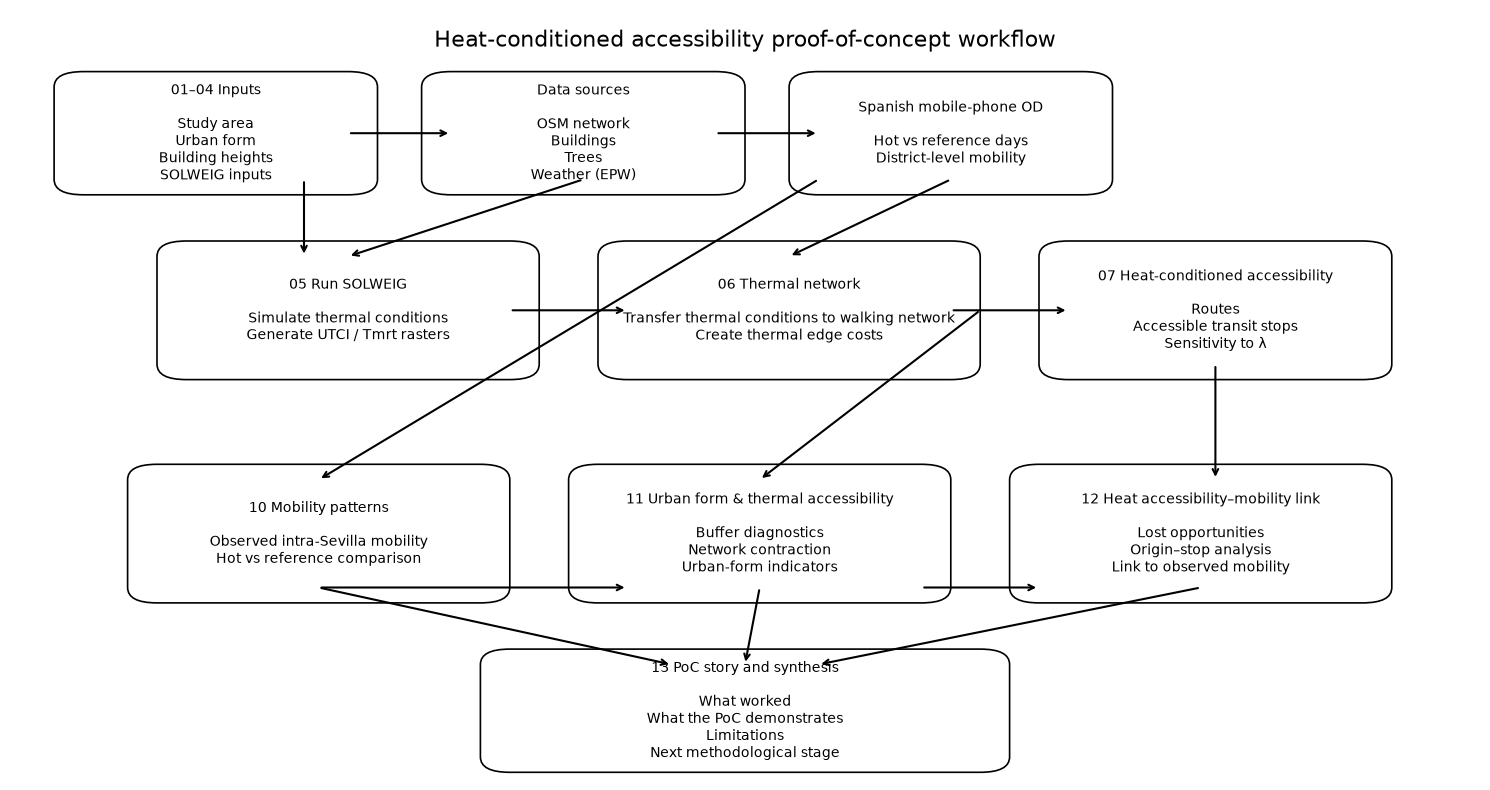

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/figures/poc_workflow_overview.png


In [16]:
from pathlib import Path
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

FIGURES = PROJECT_ROOT / "outputs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

def add_box(ax, x, y, w, h, text, fontsize=10):
    box = FancyBboxPatch(
        (x, y),
        w,
        h,
        boxstyle="round,pad=0.02",
        linewidth=1.2,
        facecolor="white",
        edgecolor="black"
    )
    ax.add_patch(box)
    ax.text(
        x + w / 2,
        y + h / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        wrap=True
    )

def add_arrow(ax, x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="->",
            lw=1.5
        )
    )

fig, ax = plt.subplots(figsize=(15, 8))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

# Row 1: inputs
add_box(ax, 0.05, 0.78, 0.18, 0.12,
        "01–04 Inputs\n\nStudy area\nUrban form\nBuilding heights\nSOLWEIG inputs")

add_box(ax, 0.30, 0.78, 0.18, 0.12,
        "Data sources\n\nOSM network\nBuildings\nTrees\nWeather (EPW)")

add_box(ax, 0.55, 0.78, 0.18, 0.12,
        "Spanish mobile-phone OD\n\nHot vs reference days\nDistrict-level mobility")

# Row 2: thermal modelling
add_box(ax, 0.12, 0.54, 0.22, 0.14,
        "05 Run SOLWEIG\n\nSimulate thermal conditions\nGenerate UTCI / Tmrt rasters")

add_box(ax, 0.42, 0.54, 0.22, 0.14,
        "06 Thermal network\n\nTransfer thermal conditions to walking network\nCreate thermal edge costs")

# Row 3: accessibility
add_box(ax, 0.72, 0.54, 0.20, 0.14,
        "07 Heat-conditioned accessibility\n\nRoutes\nAccessible transit stops\nSensitivity to λ")

# Row 4: interpretation / extension
add_box(ax, 0.10, 0.25, 0.22, 0.14,
        "10 Mobility patterns\n\nObserved intra-Sevilla mobility\nHot vs reference comparison")

add_box(ax, 0.40, 0.25, 0.22, 0.14,
        "11 Urban form & thermal accessibility\n\nBuffer diagnostics\nNetwork contraction\nUrban-form indicators")

add_box(ax, 0.70, 0.25, 0.22, 0.14,
        "12 Heat accessibility–mobility link\n\nLost opportunities\nOrigin–stop analysis\nLink to observed mobility")

# Final synthesis
add_box(ax, 0.34, 0.03, 0.32, 0.12,
        "13 PoC story and synthesis\n\nWhat worked\nWhat the PoC demonstrates\nLimitations\nNext methodological stage")

# arrows
add_arrow(ax, 0.23, 0.84, 0.30, 0.84)
add_arrow(ax, 0.48, 0.84, 0.55, 0.84)

add_arrow(ax, 0.20, 0.78, 0.20, 0.68)
add_arrow(ax, 0.39, 0.78, 0.23, 0.68)
add_arrow(ax, 0.64, 0.78, 0.53, 0.68)

add_arrow(ax, 0.34, 0.61, 0.42, 0.61)
add_arrow(ax, 0.64, 0.61, 0.72, 0.61)

add_arrow(ax, 0.82, 0.54, 0.82, 0.39)
add_arrow(ax, 0.66, 0.61, 0.51, 0.39)
add_arrow(ax, 0.55, 0.78, 0.21, 0.39)

add_arrow(ax, 0.21, 0.25, 0.42, 0.25)
add_arrow(ax, 0.62, 0.25, 0.70, 0.25)

add_arrow(ax, 0.21, 0.25, 0.45, 0.15)
add_arrow(ax, 0.51, 0.25, 0.50, 0.15)
add_arrow(ax, 0.81, 0.25, 0.55, 0.15)

ax.text(
    0.5,
    0.96,
    "Heat-conditioned accessibility proof-of-concept workflow",
    ha="center",
    va="center",
    fontsize=16
)

workflow_path = FIGURES / "poc_workflow_overview.png"
plt.tight_layout()
plt.savefig(workflow_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", workflow_path)

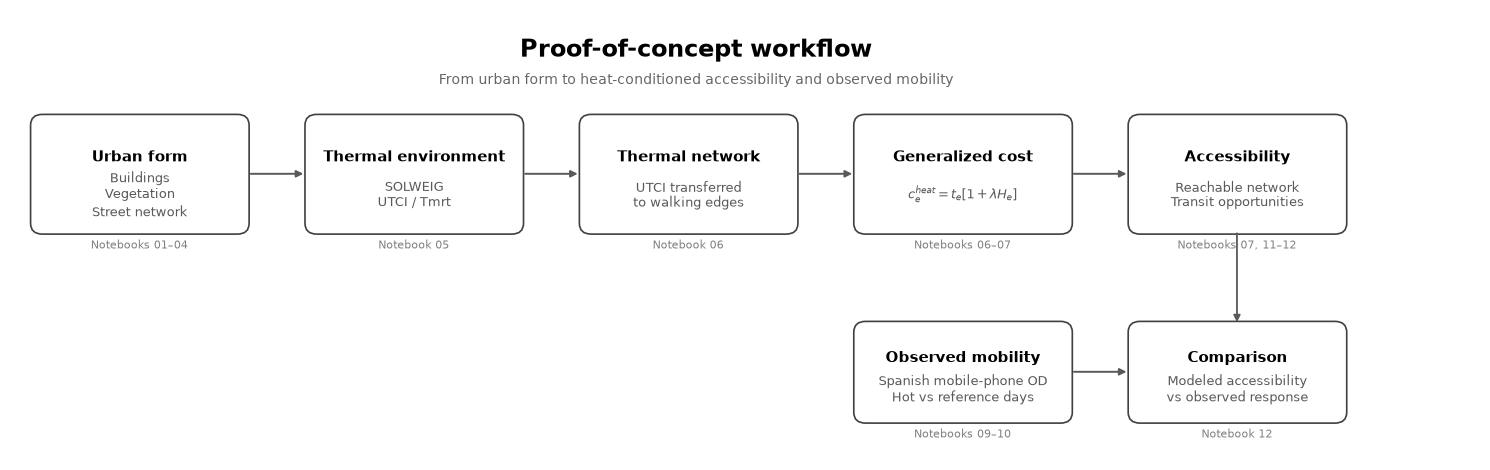

In [19]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 4.8))

ax.set_xlim(0, 15)
ax.set_ylim(0, 5)
ax.axis("off")


def workflow_box(
    x,
    y,
    width,
    height,
    title,
    subtitle
):
    box = FancyBboxPatch(
        (x, y),
        width,
        height,
        boxstyle="round,pad=0.04,rounding_size=0.12",
        linewidth=1.2,
        facecolor="white",
        edgecolor="0.25"
    )

    ax.add_patch(box)

    ax.text(
        x + width / 2,
        y + height * 0.65,
        title,
        ha="center",
        va="center",
        fontsize=11,
        fontweight="bold"
    )

    ax.text(
        x + width / 2,
        y + height * 0.32,
        subtitle,
        ha="center",
        va="center",
        fontsize=9,
        color="0.35",
        linespacing=1.3
    )


def arrow(x1, y1, x2, y2):
    ax.annotate(
        "",
        xy=(x2, y2),
        xytext=(x1, y1),
        arrowprops=dict(
            arrowstyle="-|>",
            lw=1.4,
            color="0.35",
            shrinkA=4,
            shrinkB=4
        )
    )


# ------------------------------------------------
# Main methodological chain
# ------------------------------------------------

y = 2.55
h = 1.25
w = 2.15

workflow_box(
    0.25, y, w, h,
    "Urban form",
    "Buildings\nVegetation\nStreet network"
)

workflow_box(
    3.05, y, w, h,
    "Thermal environment",
    "SOLWEIG\nUTCI / Tmrt"
)

workflow_box(
    5.85, y, w, h,
    "Thermal network",
    "UTCI transferred\nto walking edges"
)

workflow_box(
    8.65, y, w, h,
    "Generalized cost",
    r"$c_e^{heat}=t_e[1+\lambda H_e]$"
)

workflow_box(
    11.45, y, w, h,
    "Accessibility",
    "Reachable network\nTransit opportunities"
)


# Main arrows
arrow(2.40, 3.18, 3.05, 3.18)
arrow(5.20, 3.18, 5.85, 3.18)
arrow(8.00, 3.18, 8.65, 3.18)
arrow(10.80, 3.18, 11.45, 3.18)


# ------------------------------------------------
# Observed mobility layer
# ------------------------------------------------

workflow_box(
    8.65, 0.45, 2.15, 1.05,
    "Observed mobility",
    "Spanish mobile-phone OD\nHot vs reference days"
)

workflow_box(
    11.45, 0.45, 2.15, 1.05,
    "Comparison",
    "Modeled accessibility\nvs observed response"
)

arrow(10.80, 0.98, 11.45, 0.98)

# Connect modeled accessibility to comparison
ax.annotate(
    "",
    xy=(12.52, 1.50),
    xytext=(12.52, 2.55),
    arrowprops=dict(
        arrowstyle="-|>",
        lw=1.3,
        color="0.35"
    )
)


# ------------------------------------------------
# Notebook references
# ------------------------------------------------

ax.text(
    1.32, 2.35,
    "Notebooks 01–04",
    ha="center",
    fontsize=8,
    color="0.5"
)

ax.text(
    4.12, 2.35,
    "Notebook 05",
    ha="center",
    fontsize=8,
    color="0.5"
)

ax.text(
    6.92, 2.35,
    "Notebook 06",
    ha="center",
    fontsize=8,
    color="0.5"
)

ax.text(
    9.72, 2.35,
    "Notebooks 06–07",
    ha="center",
    fontsize=8,
    color="0.5"
)

ax.text(
    12.52, 2.35,
    "Notebooks 07, 11–12",
    ha="center",
    fontsize=8,
    color="0.5"
)

ax.text(
    9.72, 0.25,
    "Notebooks 09–10",
    ha="center",
    fontsize=8,
    color="0.5"
)

ax.text(
    12.52, 0.25,
    "Notebook 12",
    ha="center",
    fontsize=8,
    color="0.5"
)


# ------------------------------------------------
# Title
# ------------------------------------------------

ax.text(
    7.0,
    4.55,
    "Proof-of-concept workflow",
    ha="center",
    va="center",
    fontsize=17,
    fontweight="bold"
)

ax.text(
    7.0,
    4.22,
    "From urban form to heat-conditioned accessibility and observed mobility",
    ha="center",
    va="center",
    fontsize=10,
    color="0.4"
)

plt.tight_layout()
plt.show()

### How to read this workflow

The proof-of-concept begins with urban-form and network inputs, which are used to prepare the thermal simulation environment.

SOLWEIG is then used to generate spatial thermal outputs, especially UTCI-related raster surfaces. These thermal conditions are transferred to the pedestrian network to create thermally adjusted walking costs.

The adjusted network is used to evaluate route change, transit-stop accessibility loss, and sensitivity to the thermal penalty parameter.

In parallel, Spanish mobile-phone OD data provide an observational layer for comparing hot-day and reference-day mobility patterns.

The later notebooks extend the proof-of-concept by examining urban-form diagnostics, network contraction, lost opportunities, and the emerging link between modeled accessibility loss and observed mobility change.

In [18]:
ax.text(0.14, 0.92, "Stage A — Inputs", fontsize=12, ha="center")
ax.text(0.38, 0.70, "Stage B — Thermal modelling", fontsize=12, ha="center")
ax.text(0.79, 0.70, "Stage C — Accessibility modelling", fontsize=12, ha="center")
ax.text(0.50, 0.42, "Stage D — Interpretation and validation", fontsize=12, ha="center")

Text(0.5, 0.42, 'Stage D — Interpretation and validation')

## 1. Methodological idea

Conventional accessibility measures generally treat travel cost as a function of distance or travel time:

\[
A_i = \sum_j O_j f(c_{ij})
\]

This proof-of-concept modifies walking cost by incorporating thermal stress:

\[
c_e^{heat}
=
t_e
\left[
1 + \lambda \max(UTCI_e - 32, 0)
\right]
\]

where:

- \(t_e\) is conventional walking time;
- \(UTCI_e\) is modeled thermal stress on the network edge;
- \(32^\circ C\) is the selected heat-stress threshold;
- \(\lambda\) is a sensitivity parameter controlling the thermal penalty.

The parameter \(\lambda\) is not behaviorally calibrated in the current proof-of-concept and should therefore be interpreted as a sensitivity parameter.

In [11]:
from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

ACCESS_DIR = PROJECT_ROOT / "outputs" / "accessibility"
SOLWEIG_DIR = PROJECT_ROOT / "outputs" / "solweig" / "summary"
INTERIM = PROJECT_ROOT / "data" / "interim"
MOBILE = PROJECT_ROOT / "data" / "mobile" / "processed"

sensitivity = pd.read_csv(
    ACCESS_DIR / "accessibility_sensitivity.csv"
)

access = pd.read_csv(
    ACCESS_DIR / "origin_accessibility_lambda_005.csv"
)

routes = pd.read_csv(
    ACCESS_DIR / "route_results_lambda_005.csv"
)

In [12]:
from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox

PROJECT_ROOT = Path(
    "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
)

ACCESS_DIR = PROJECT_ROOT / "outputs" / "accessibility"
SOLWEIG_DIR = PROJECT_ROOT / "outputs" / "solweig" / "summary"
INTERIM = PROJECT_ROOT / "data" / "interim"
MOBILE = PROJECT_ROOT / "data" / "mobile" / "processed"

sensitivity = pd.read_csv(
    ACCESS_DIR / "accessibility_sensitivity.csv"
)

access = pd.read_csv(
    ACCESS_DIR / "origin_accessibility_lambda_005.csv"
)

routes = pd.read_csv(
    ACCESS_DIR / "route_results_lambda_005.csv"
)

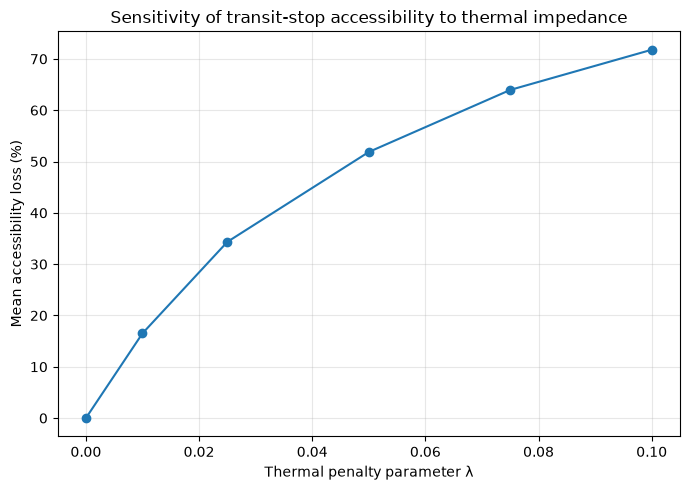

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(
    sensitivity["lambda"],
    sensitivity["mean_access_loss_pct"],
    marker="o"
)

ax.set_xlabel("Thermal penalty parameter λ")
ax.set_ylabel("Mean accessibility loss (%)")
ax.set_title(
    "Sensitivity of transit-stop accessibility to thermal impedance"
)

ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Early interpretation

Accessibility declines monotonically as the thermal penalty increases.

At \(\lambda = 0.05\), mean modeled transit-stop accessibility declines by approximately 52% across the sampled origins.

This value should not be interpreted as a citywide estimate for Sevilla. It reflects the selected proof-of-concept study area, thermal surface, accessibility budget, and sensitivity parameter.

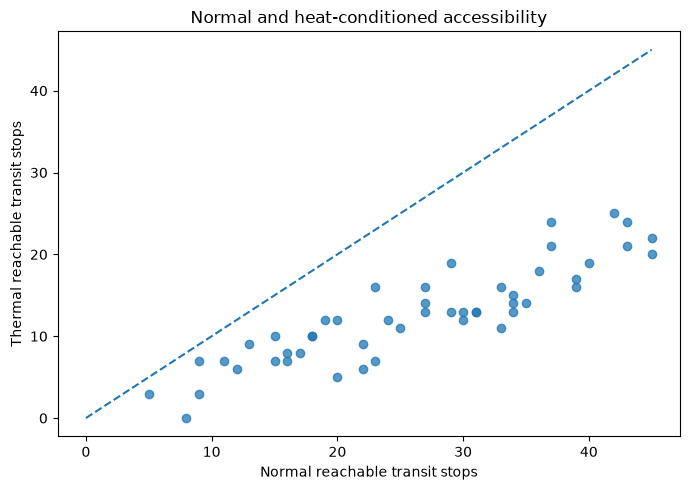

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    access["normal_access"],
    access["thermal_access"],
    alpha=0.75
)

max_val = max(
    access["normal_access"].max(),
    access["thermal_access"].max()
)

ax.plot(
    [0, max_val],
    [0, max_val],
    linestyle="--"
)

ax.set_xlabel("Normal reachable transit stops")
ax.set_ylabel("Thermal reachable transit stops")
ax.set_title(
    "Normal and heat-conditioned accessibility"
)

plt.tight_layout()
plt.show()

Most origins fall below the 1:1 line, indicating that thermal impedance reduces the number of transit opportunities reachable within the fixed 10-minute generalized-cost budget.

### Opportunity-loss mechanism

The current proof-of-concept shows a sharp increase in opportunity loss beyond approximately 6–7 minutes of conventional walking time.

This breakpoint is largely produced by the current thermal-cost structure. The mean thermal cost ratio across the modeled network is approximately 1.48, meaning that a 600-second thermal budget corresponds to approximately 406 seconds, or 6.8 minutes, of conventional walking time.

This therefore validates the internal model mechanism rather than demonstrating a universal behavioral walking threshold.

In [15]:
urban_corr = pd.DataFrame({
    "Variable": [
        "Building density",
        "Mean building height",
        "Tree density",
        "Mean local UTCI"
    ],
    "Spearman with accessibility loss": [
        -0.062,
        -0.295,
        0.191,
        -0.140
    ]
})

urban_corr

,Variable,Spearman with accessibility loss
0,Building density,-0.062
1,Mean building height,-0.295
2,Tree density,0.191
3,Mean local UTCI,-0.140


### Urban-form diagnostic

Simple 250 m origin-neighborhood urban-form indicators showed weak direct relationships with accessibility loss.

However, tree density showed a clearer negative association with modeled UTCI.

This suggests that urban form may influence thermal conditions, while accessibility loss depends on thermal conditions distributed across the reachable network rather than only around the origin.

## Observed mobility response

Spanish mobile-phone OD data were used as an independent observational layer.

Across the selected hot and reference weekdays:

- mean matched-day mobility change: approximately **−15.7%**
- morning change: approximately **−10.9%**
- afternoon change: approximately **−18.3%**
- evening change: approximately **−17.1%**

These results are descriptive and should not be interpreted causally.

The mobility analysis covers all 11 Sevilla districts, whereas the current thermal-accessibility proof-of-concept covers only a small portion of the urban area.

Therefore, the current accessibility and mobility results should not yet be treated as directly comparable citywide effects.

## What the proof-of-concept demonstrates

The current workflow demonstrates that:

1. Urban-form data can be converted into a spatial thermal model.
2. Modeled thermal stress can be transferred onto a pedestrian network.
3. Thermal stress can be incorporated directly into generalized walking cost.
4. Thermal impedance can change selected walking routes.
5. Heat-conditioned impedance reduces the spatial reach of a fixed walking-cost budget.
6. Reduced network reach translates into loss of reachable transit opportunities.
7. Accessibility results respond systematically to the thermal penalty parameter.
8. Opportunity-level analysis reveals how marginal transit opportunities disappear as generalized walking cost increases.
9. Local urban-form metrics alone do not explain accessibility loss well, indicating that network-scale thermal context matters.
10. Observed hot-day mobility reductions provide a promising independent validation layer for a future city-scale analysis.

## Current limitations

The proof-of-concept should be interpreted cautiously because:

- the thermal simulation covers only a small part of Sevilla;
- the meteorological input is based on a typical meteorological year rather than an observed extreme event;
- the current thermal surface uses cell-wise daily maximum UTCI;
- daily-maximum UTCI produces relatively homogeneous severe thermal penalties across much of the modeled network;
- \(\lambda\) is a sensitivity parameter rather than a behaviorally calibrated coefficient;
- the current accessibility opportunity measure is based on transit-stop counts;
- the mobile-phone analysis operates at a much larger spatial scale than the thermal accessibility model.

## Next methodological stage

The next stage should expand the thermal-accessibility model spatially and introduce common-hour thermal surfaces.

A stronger city-scale analysis would use:

**urban form → UTCI at a common hot-afternoon hour → heterogeneous edge-level thermal impedance → accessibility loss → district-level mobility response**

Candidate thermal snapshots include 14:00, 15:00, and 16:00 on observed hot days.

This would allow the model to capture spatial variation in shading and urban morphology more effectively and enable a more meaningful comparison with observed mobility patterns.

## Proof-of-concept takeaway

The proof-of-concept shows that environmental stress can be embedded directly into accessibility impedance rather than treated only as an external exposure variable.

The current results demonstrate the computational feasibility and internal consistency of this approach, while also identifying the thermal representation and spatial scale that need refinement before citywide interpretation.